# 05 · The cylinder problem

Section 3.3 of the thesis [`lavado2012phd`] and the corresponding study in [`lavado2011ijam`]. A known nonlinear data structure is simulated:
twelve variables, ten of them nonlinear functions of the other two. The "cylinder problem" was used by Winsberg & Ramsay
[`winsberg1983monotone`], by Gifi [`gifi1991nonlinear`] and others to test nonlinear variants of PCA.

> **What is exact and what is not.** Nothing in this notebook is an *exact* replication. The original random draws are lost, the thesis does not
> state the distribution of the height $a$ and base area $b$ (here $a,b\sim U(0,1)$, an inference from the ranges printed in the thesis figures),
> and the scale on which the noise standard deviation is measured is ambiguous (see §2). The targets are therefore **qualitative**: the ordering PCA $\ll$
> qlPCA$_2\lesssim$ qlPCA$_3$, the effect of noise, and the order of magnitude of the percentages in thesis Table 3.3. Chapter 4 (notebook 06) is the exact replication.

*Contents:* 1. the problem and its linearising transformations · 2. one simulated data set, three noise levels (Table 3.3) ·
3. many draws · 4. scree plots (Figs 3.4–3.6) · 5. optimal transformations (Fig. 3.7) · 6. knot placement for variable 12 · References.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qlpca import QLPCA
from qlpca.datasets import make_cylinder, CYLINDER_VARIABLES
from qlpca.plots import set_style, scree_plot, transformation_plots, BLUE, ORANGE, INK, INK2, GRID

set_style()
np.set_printoptions(precision=2, suppress=True, linewidth=120)

## 1 · The problem and its linearising transformations

For a cylinder with height $a$ and base area $b$ (thesis Table 3.2):

| # | variable | formula | | # | variable | formula |
|---|---|---|---|---|---|---|
| 1 | height | $a$ | | 7 | slenderness ratio | $a/\sqrt{2b\pi}$ |
| 2 | base area | $b$ | | 8 | diagonal–base angle | $\arctan\!\big[a\sqrt\pi/(2\sqrt b)\big]$ |
| 3 | base perimeter | $2\sqrt{b\pi}$ | | 9 | diagonal–side angle | $\operatorname{arccot}\!\big[a\sqrt\pi/(2\sqrt b)\big]$ |
| 4 | lateral area | $2a\sqrt{b\pi}$ | | 10 | electrical resistance | $a/b$ |
| 5 | volume | $ab$ | | 11 | conductance | $b/a$ |
| 6 | moment of inertia | $ab^2/2\pi$ | | 12 | torsional deformability | $2a\pi/b^2$ |

Every variable becomes linear in $\log a$ and $\log b$ after the **linearising transformation**: the logarithm for variables 1–7 and 10–12, and
$\log\tan$ and $\log\cot$ for the two angles. The transformed matrix therefore has rank two, so a nonlinear PCA on the original matrix —
as well as a linear PCA on the transformed matrix — should fit almost perfectly with two dimensions, and the optimal spline transformations should look logarithmic.
The cell below confirms the rank-two structure on a simulated data set.

In [2]:
X0, _ = make_cylinder(51, noise=0, random_state=0)         # n = 51 cylinders, no noise
L = np.log(X0)
L[:, 7] = np.log(np.tan(X0[:, 7]))                            # log(tan) for the angle of variable 8
L[:, 8] = -np.log(np.tan(X0[:, 8]))                           # log(cot) = -log(tan) for variable 9 (sign immaterial)
s = np.linalg.svd(L - L.mean(0), compute_uv=False)
print("singular values of the centred linearised matrix:", s.round(3))
print("rank (singular values > 1e-8 x largest):", int((s > 1e-8 * s[0]).sum()))

singular values of the centred linearised matrix: [26.31 23.14  0.    0.    0.    0.    0.    0.    0.    0.    0.    0.  ]
rank (singular values > 1e-8 x largest): 2


## 2 · One simulated data set, three noise levels

Thesis Table 3.3 gives the percentage of variance explained by two components for three scenarios, one data set of 51 cylinders each time:
no noise, and normal noise with standard deviation 10 % and 25 % of the standard deviation of the variable. Two qlPCA with linear splines were fitted:
qlPCA$_2$ with two interior knots (about the 33rd and 67th percentiles) and qlPCA$_3$ with three (the quartiles) — the number of knots chosen to
keep at least 5 observations per basis function with $n=51$.

**Noise scale — a decision pending.** The thesis says that each variable was first transformed by its linearising transformation, noise was added,
and the result transformed back, with a standard deviation equal to 10 % or 25 % "of the standard deviation of each original variable".
Read literally, "original" would be the variable on its *natural* scale, which is incompatible with adding the noise on the linearised scale:
variable 12 has a standard deviation of more than 1000 on its natural scale, against about 2 on the log scale, so 25 % of it would be a noise of
hundreds of log-units. `make_cylinder` therefore measures the standard deviation **on the linearised scale** (noise of $10$ %/$25$ % of the standard
deviation of $\log$ of the variable). This is flagged for the author in the docstring and in docs/SPEC.md §9.

In [3]:
print("variable 12: sd on the natural scale = %.0f, sd of its logarithm = %.2f" % (X0[:, 11].std(ddof=1), np.log(X0[:, 11]).std(ddof=1)))

thesis = {0.0: (82.15, 97.77, 98.43), 0.10: (80.18, 96.90, 97.68), 0.25: (72.62, 92.59, 94.41)}
print("\nnoise    method     this draw (seed 0)   thesis Table 3.3")
draw = {}
for noise in thesis:
    X, _ = make_cylinder(51, noise, random_state=0)
    draw[noise] = X
    fits = [QLPCA(2, n_knots=0).fit(X), QLPCA(2, n_knots=2, random_state=0).fit(X), QLPCA(2, n_knots=3, random_state=0).fit(X)]
    for lab, f, t in zip(("PCA   ", "qlPCA2", "qlPCA3"), fits, thesis[noise]):
        print(f"{noise:4.0%}    {lab}     {100 * f.eigenvalues_.sum() / 12:12.2f}        {t:8.2f}")

variable 12: sd on the natural scale = 1314, sd of its logarithm = 1.98

noise    method     this draw (seed 0)   thesis Table 3.3


  0%    PCA               82.16           82.15
  0%    qlPCA2            97.42           97.77
  0%    qlPCA3            98.24           98.43


 10%    PCA               79.51           80.18
 10%    qlPCA2            96.03           96.90
 10%    qlPCA3            97.09           97.68


 25%    PCA               69.54           72.62
 25%    qlPCA2            91.73           92.59
 25%    qlPCA3            93.36           94.41


The percentages are of the same order as in the thesis for every scenario, and the ordering is the same: the qlPCA captures the nonlinear structure
(≈ 97 % against ≈ 80 % for PCA without noise), noise reduces the explained variance of all methods, and three knots help most where the noise is largest.
A single draw says little about how much of the difference with the thesis is chance, so the next section repeats the experiment.

## 3 · Many draws

Fifty independent data sets (seeds 0–49) per scenario. The table gives the mean and the range of the percentage of variance explained by two components;
the figure shows each draw and the thesis value.

In [4]:
n_draws = 50
sim = {}
for noise in thesis:
    rows = []
    for seed in range(n_draws):
        X, _ = make_cylinder(51, noise, random_state=seed)
        rows.append([100 * QLPCA(2, n_knots=r, n_init=4 if r else 0, random_state=0).fit(X).eigenvalues_.sum() / 12 for r in (0, 2, 3)])
    sim[noise] = np.array(rows)

print("noise  method   mean    min    max   | thesis   within range?")
for noise in thesis:
    for k, lab in enumerate(("PCA   ", "qlPCA2", "qlPCA3")):
        v = sim[noise][:, k]
        t = thesis[noise][k]
        print(f"{noise:4.0%}  {lab}  {v.mean():6.2f} {v.min():6.2f} {v.max():6.2f}  | {t:6.2f}   {'yes' if v.min() <= t <= v.max() else 'NO'}")

noise  method   mean    min    max   | thesis   within range?
  0%  PCA      82.67  76.74  89.99  |  82.15   yes
  0%  qlPCA2   98.14  96.76  99.33  |  97.77   yes
  0%  qlPCA3   98.80  97.95  99.65  |  98.43   yes
 10%  PCA      80.95  74.86  89.09  |  80.18   yes
 10%  qlPCA2   96.95  94.98  98.58  |  96.90   yes
 10%  qlPCA3   97.79  96.33  98.99  |  97.68   yes
 25%  PCA      73.47  66.36  82.52  |  72.62   yes
 25%  qlPCA2   92.57  88.65  95.40  |  92.59   yes
 25%  qlPCA3   93.92  90.16  95.86  |  94.41   yes


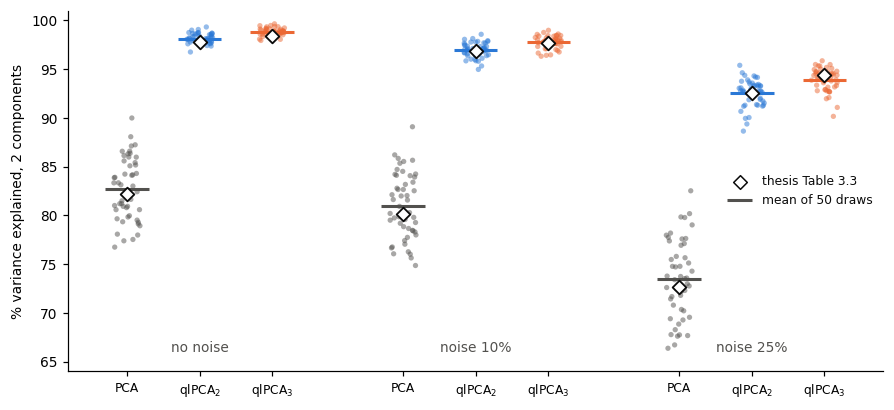

In [5]:
fig, ax = plt.subplots(figsize=(8.2, 3.8))
rng = np.random.default_rng(0)
cols = (INK2, BLUE, ORANGE)
pos = 0
ticks, labels = [], []
for noise in thesis:
    for k, lab in enumerate(("PCA", "qlPCA$_2$", "qlPCA$_3$")):
        v = sim[noise][:, k]
        ax.scatter(pos + rng.uniform(-0.18, 0.18, len(v)), v, s=12, color=cols[k], alpha=0.5, edgecolor="none")
        ax.hlines(v.mean(), pos - 0.3, pos + 0.3, color=cols[k], lw=2)
        ax.scatter([pos], [thesis[noise][k]], marker="D", s=40, color="white", edgecolor=INK, linewidth=1.2, zorder=5)
        ticks.append(pos); labels.append(lab); pos += 1
    pos += 0.8
ax.set_xticks(ticks); ax.set_xticklabels(labels, fontsize=8)
for i, noise in enumerate(thesis):
    ax.text(1 + i * 3.8, 66, f"noise {noise:.0%}" if noise else "no noise", ha="center", fontsize=9, color=INK2)
ax.set_ylabel("% variance explained, 2 components"); ax.set_ylim(64, 101)
ax.scatter([], [], marker="D", s=40, color="white", edgecolor=INK, label="thesis Table 3.3")
ax.hlines([], 0, 0, color=INK2, lw=2, label="mean of 50 draws"); ax.legend(loc="center right", fontsize=8)
for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.show()

In every scenario the thesis values fall within the simulated range, and the means are within about one percentage point of them. This supports
$a,b\sim U(0,1)$ and the linearised noise scale as reasonable readings, but it does not prove them: other assumptions could give similar numbers.

## 4 · Scree plots (thesis Figures 3.4–3.6)

In the worst scenario (noise 25 %) the thesis uses scree plots to check that two components are appropriate. For the PCA the eigenvalues are those of the
correlation matrix of the original variables; for qlPCA those of the correlation matrix of the *transformed* variables. Since qlPCA solutions are **not nested**,
a scree plot is drawn for the solution with two retained components and another for the solution with three.

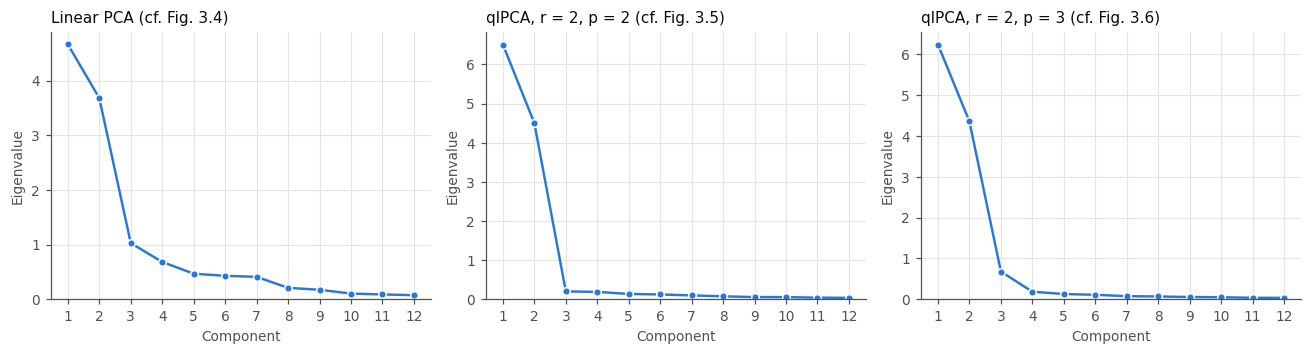

In [6]:
Xn = draw[0.25]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3), sharey=False)
scree_plot(np.linalg.eigvalsh(np.corrcoef(Xn.T))[::-1], ax=axes[0], kaiser=False, title="Linear PCA (cf. Fig. 3.4)")
scree_plot(QLPCA(2, n_knots=2, random_state=0).fit(Xn), ax=axes[1], kaiser=False, title="qlPCA, r = 2, p = 2 (cf. Fig. 3.5)")
scree_plot(QLPCA(3, n_knots=2, random_state=0).fit(Xn), ax=axes[2], kaiser=False, title="qlPCA, r = 2, p = 3 (cf. Fig. 3.6)")
plt.tight_layout(); plt.show()

In the thesis the linear PCA scree plot (Fig. 3.4) is ambiguous: the slope changes abruptly twice, at the third and at the sixth component, so keeping two or
five components could be defended. **This is not reproduced by this draw**: here the PCA scree plot has one clear break at the third component followed by a gentler
bend later, so it already points to two components. What is reproduced is the qlPCA result: a sharp break after the second component, with the remaining
eigenvalues almost flat, for both the two- and the three-component solutions. (The scree plot of a single noisy draw can differ in detail from the thesis figure.)

## 5 · Optimal transformations (thesis Figure 3.7)

Thesis Figure 3.7 shows the optimal spline transformations of variables 6 and 12 for the qlPCA with three interior knots on the data without noise:
the first is "logarithmic as expected" and representative of all the others, the second is the exception. The figure below reproduces the idea for the
simulated draw; the grey curve is the standardised logarithm, the known linearising transformation.

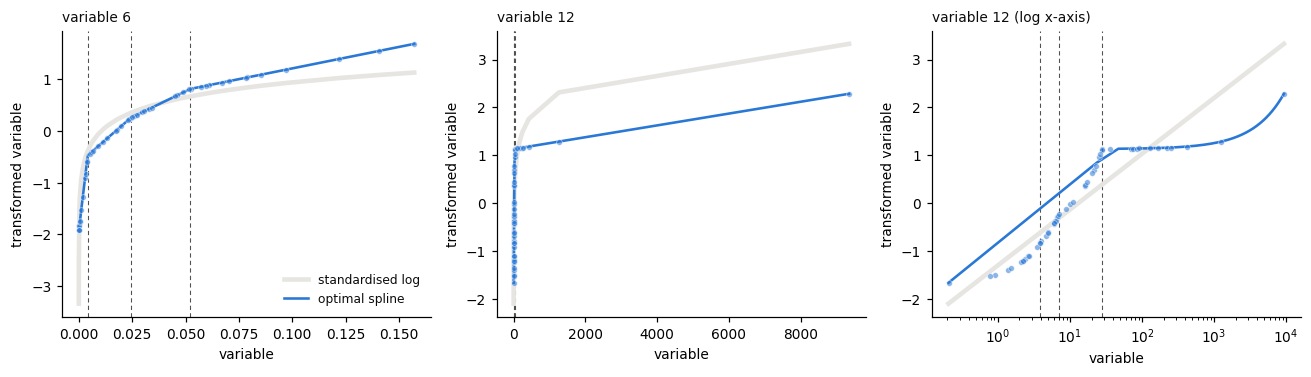

variable 12: interior knots (quartiles) = [ 3.84  7.12 28.14] | maximum = 9350.9 | thesis draw: knots 3.85, 10.32, 25.38; maximum 6498.7
communalities, variables 1..12: [0.98 0.97 0.98 0.98 0.98 0.99 0.99 0.99 0.99 0.99 0.98 0.95]


In [7]:
X, _ = make_cylinder(51, 0, random_state=0)
q3 = QLPCA(2, degree=1, n_knots=3, random_state=0).fit(X)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, j, xscale in ((axes[0], 5, "linear"), (axes[1], 11, "linear"), (axes[2], 11, "log")):
    xg, fg = q3.variable_transformation(j, 400)
    lg = np.log(X[:, j]); lgz = (lg - lg.mean()) / lg.std(ddof=1)
    o = np.argsort(X[:, j])
    ax.plot(X[o, j], lgz[o], color=GRID, lw=3.0, label="standardised log", zorder=1)
    ax.plot(xg, fg, color=BLUE, lw=1.7, label="optimal spline", zorder=3)
    ax.scatter(X[:, j], q3.transformed_[:, j], s=14, color=BLUE, alpha=0.55, edgecolor="white", linewidth=0.5, zorder=4)
    for k in np.unique(q3.knots_[j])[1:-1]:
        ax.axvline(k * q3.std_[j] + q3.mean_[j], color=INK2, lw=0.7, ls=(0, (4, 3)), zorder=0)
    ax.set_xscale(xscale)
    ax.set_title(f"variable {j + 1}" + (" (log x-axis)" if xscale == "log" else ""), loc="left", fontsize=9)
    ax.set_xlabel("variable"); ax.set_ylabel("transformed variable")
    for s_ in ("top", "right"): ax.spines[s_].set_visible(False)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
k12 = np.unique(q3.knots_[11])[1:-1] * q3.std_[11] + q3.mean_[11]
print("variable 12: interior knots (quartiles) =", k12.round(2), "| maximum =", X[:, 11].max().round(1),
      "| thesis draw: knots 3.85, 10.32, 25.38; maximum 6498.7")
print("communalities, variables 1..12:", q3.communalities_.round(3))

Variable 6 follows the logarithm closely, like the other variables. Variable 12 is extremely skewed ($2a\pi/b^2$ explodes when $b$ is small): three of the four
intervals between knots hold the bulk of the sample while the last one stretches from the third quartile to a maximum in the thousands, a few observations carry
the whole top segment, and the fitted transformation is less log-like there. The knots fall at about the same place as in the thesis draw (3.85; the others differ
with the draw). All transformations:

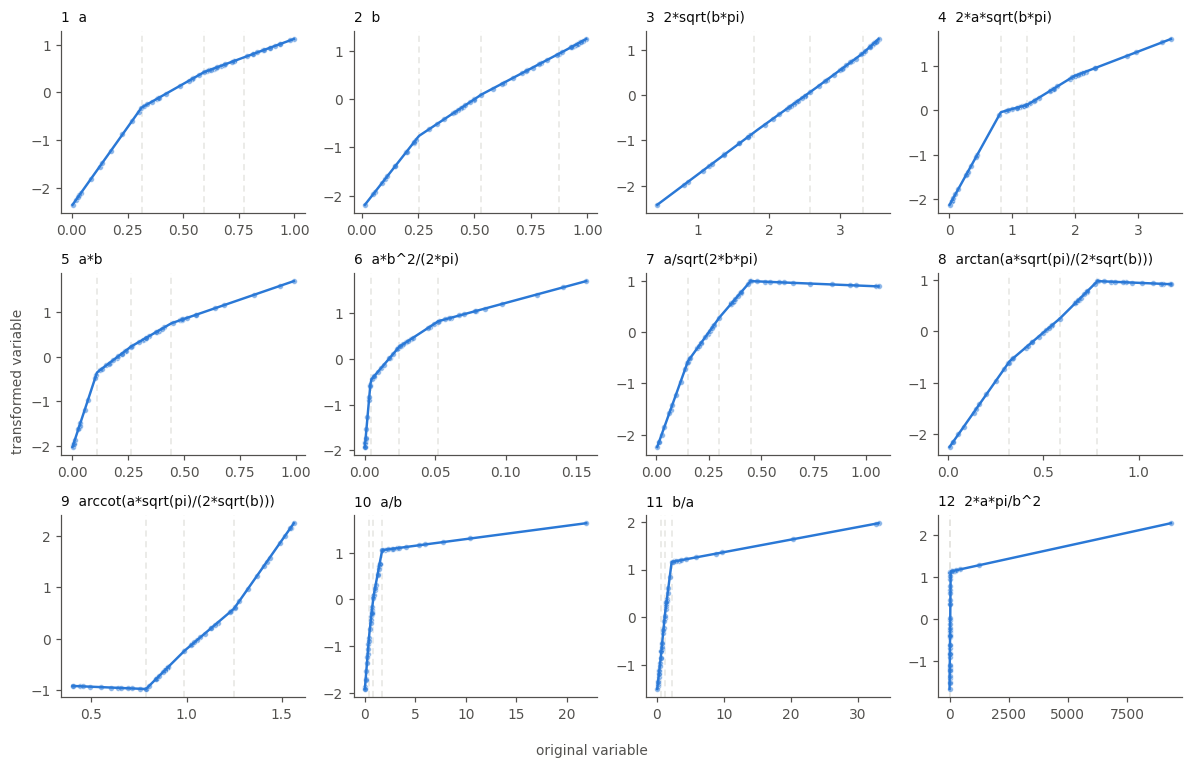

In [8]:
labels = [f"{i + 1}  {nm}" for i, nm in enumerate(CYLINDER_VARIABLES)]
fig = transformation_plots(q3, X, labels, ncols=4, figsize=(11, 7))
plt.show()

## 6 · Knot placement for variable 12

The thesis remarks that variable 12 "is an example in which an alternative location of the knots could have improved the transformation". The package
accepts explicit interior knots per variable (docs/DESIGN.md D8). The next cell moves the knots of variable 12 towards the tail (percentiles 50, 75, 90 instead
of the quartiles) and leaves the other variables unchanged.

In [9]:
def with_knots_for_12(percentiles):
    kn = [np.percentile(X[:, j], [25, 50, 75], method="hazen") for j in range(12)]   # the quartiles, as before
    kn[11] = np.percentile(X[:, 11], percentiles, method="hazen")
    return QLPCA(2, degree=1, knots=kn, random_state=0).fit(X)

base = QLPCA(2, degree=1, n_knots=3, random_state=0).fit(X)
moved = with_knots_for_12([50, 75, 90])
print("knots of variable 12 at the quartiles : VAF = %.2f %%, communality of variable 12 = %.3f" % (100 * base.eigenvalues_.sum() / 12, base.communalities_[11]))
print("knots at percentiles 50, 75, 90       : VAF = %.2f %%, communality of variable 12 = %.3f" % (100 * moved.eigenvalues_.sum() / 12, moved.communalities_[11]))

knots of variable 12 at the quartiles : VAF = 98.24 %, communality of variable 12 = 0.955
knots at percentiles 50, 75, 90       : VAF = 98.51 %, communality of variable 12 = 0.980


Moving the knots towards the tail does raise the communality of variable 12 and the total variance explained slightly, in line with the thesis remark. The gain
is small here because the other eleven variables already determine the two dimensions well. This is one draw, not a systematic study of knot placement.

## References

* `lavado2012phd` — N. Lavado, PhD thesis, ISCTE-IUL, 2012. §3.3, Tables 3.2–3.3, Figs 3.4–3.7.
* `lavado2011ijam` — N. Lavado & T. Calapez, IJAM 41(4), 2011 (the cylinder study in English).
* `winsberg1983monotone` — S. Winsberg & J. Ramsay, Monotone spline transformations for dimension reduction, *Psychometrika* 48, 1983 (origin of the cylinder problem).
* `gifi1991nonlinear` — A. Gifi, *Nonlinear Multivariate Analysis*, Wiley, 1991.